Week 6 Decision trees and random forests

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Helper function to convert NOAA damage strings
def parse_damage(val):
    if pd.isna(val):
        return 0.0
    val_str = str(val).strip().upper()
    if val_str.endswith('K'):
        return float(val_str[:-1]) * 1_000
    elif val_str.endswith('M'):
        return float(val_str[:-1]) * 1_000_000
    elif val_str.endswith('B'):
        return float(val_str[:-1]) * 1_000_000_000
    try:
        return float(val_str)
    except ValueError:
        return 0.0

# 1. Load dataset
print("Loading capstone_2023_merged.csv...")
df = pd.read_csv("capstone_2023_merged.csv", low_memory=False)

if 'DAMAGE_PROPERTY' in df.columns:
    df['DAMAGE_PROPERTY_NUMERIC'] = df['DAMAGE_PROPERTY'].apply(parse_damage)

# Target ($10k threshold) and features
target_col = 'amountPaidOnBuildingClaim' if 'amountPaidOnBuildingClaim' in df.columns else 'amountPaidOnTotalClaim'
y_binary = (pd.to_numeric(df[target_col], errors='coerce').fillna(0) >= 10000).astype(int)

feature_cols = ['DAMAGE_PROPERTY_NUMERIC', 'primary_landcover_code', 'alternate_landcover_code']
feature_cols = [c for c in feature_cols if c in df.columns]

X = df[feature_cols].fillna(df[feature_cols].median(numeric_only=True))

# Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.2, random_state=42, stratify=y_binary)

print("\n--- Training Week 6 Models ---")

# --- 1. Single Decision Tree (Controlled Regularization) ---
print("Fitting Decision Tree Classifier (max_depth=5)...")
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

# --- 2. Random Forest Ensemble ---
print("Fitting Random Forest Classifier (n_estimators=100, max_depth=8)...")
rf = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=10, max_features='sqrt', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Feature Importances Extraction
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n=== Random Forest Feature Importances ===")
print(importances.to_string(index=False))

# Evaluation Metrics
results_w6 = pd.DataFrame({
    'Model Architecture': ['Decision Tree (max_depth=5)', 'Random Forest Ensemble (100 Trees)'],
    'Accuracy': [accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_rf)],
    'Precision': [precision_score(y_test, y_pred_dt, zero_division=0), precision_score(y_test, y_pred_rf, zero_division=0)],
    'Recall': [recall_score(y_test, y_pred_dt, zero_division=0), recall_score(y_test, y_pred_rf, zero_division=0)],
    'F1-Score': [f1_score(y_test, y_pred_dt, zero_division=0), f1_score(y_test, y_pred_rf, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test, y_prob_dt), roc_auc_score(y_test, y_prob_rf)]
})

print("\n=== Week 6 Model Comparison Results ===")
print(results_w6.to_string(index=False))

# Save Image Table
fig, ax = plt.subplots(figsize=(12, 2.5), dpi=300)
ax.axis('off')

table = ax.table(
    cellText=np.round(results_w6.iloc[:, 1:].values, 4),
    rowLabels=results_w6['Model Architecture'].values,
    colLabels=results_w6.columns[1:],
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

for (row, col), cell in table.get_celld().items():
    if row == 0 or col == -1:
        cell.set_facecolor('#40466e')
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#f5f5f5' if row % 2 == 0 else 'white')

plt.savefig('week6_model_comparison.png', bbox_inches='tight', pad_inches=0.1)
plt.close()

print("\nSuccess! Saved Week 6 comparison table image as 'week6_model_comparison.png'")

Loading capstone_2023_merged.csv...

--- Training Week 6 Models ---
Fitting Decision Tree Classifier (max_depth=5)...
Fitting Random Forest Classifier (n_estimators=100, max_depth=8)...

=== Random Forest Feature Importances ===
                 Feature  Importance
 DAMAGE_PROPERTY_NUMERIC    0.818920
alternate_landcover_code    0.091408
  primary_landcover_code    0.089672

=== Week 6 Model Comparison Results ===
                Model Architecture  Accuracy  Precision   Recall  F1-Score  ROC-AUC
       Decision Tree (max_depth=5)  0.552582   0.553929 0.978254  0.707335 0.527616
Random Forest Ensemble (100 Trees)  0.554056   0.553822 0.993743  0.711255 0.526886

Success! Saved Week 6 comparison table image as 'week6_model_comparison.png'


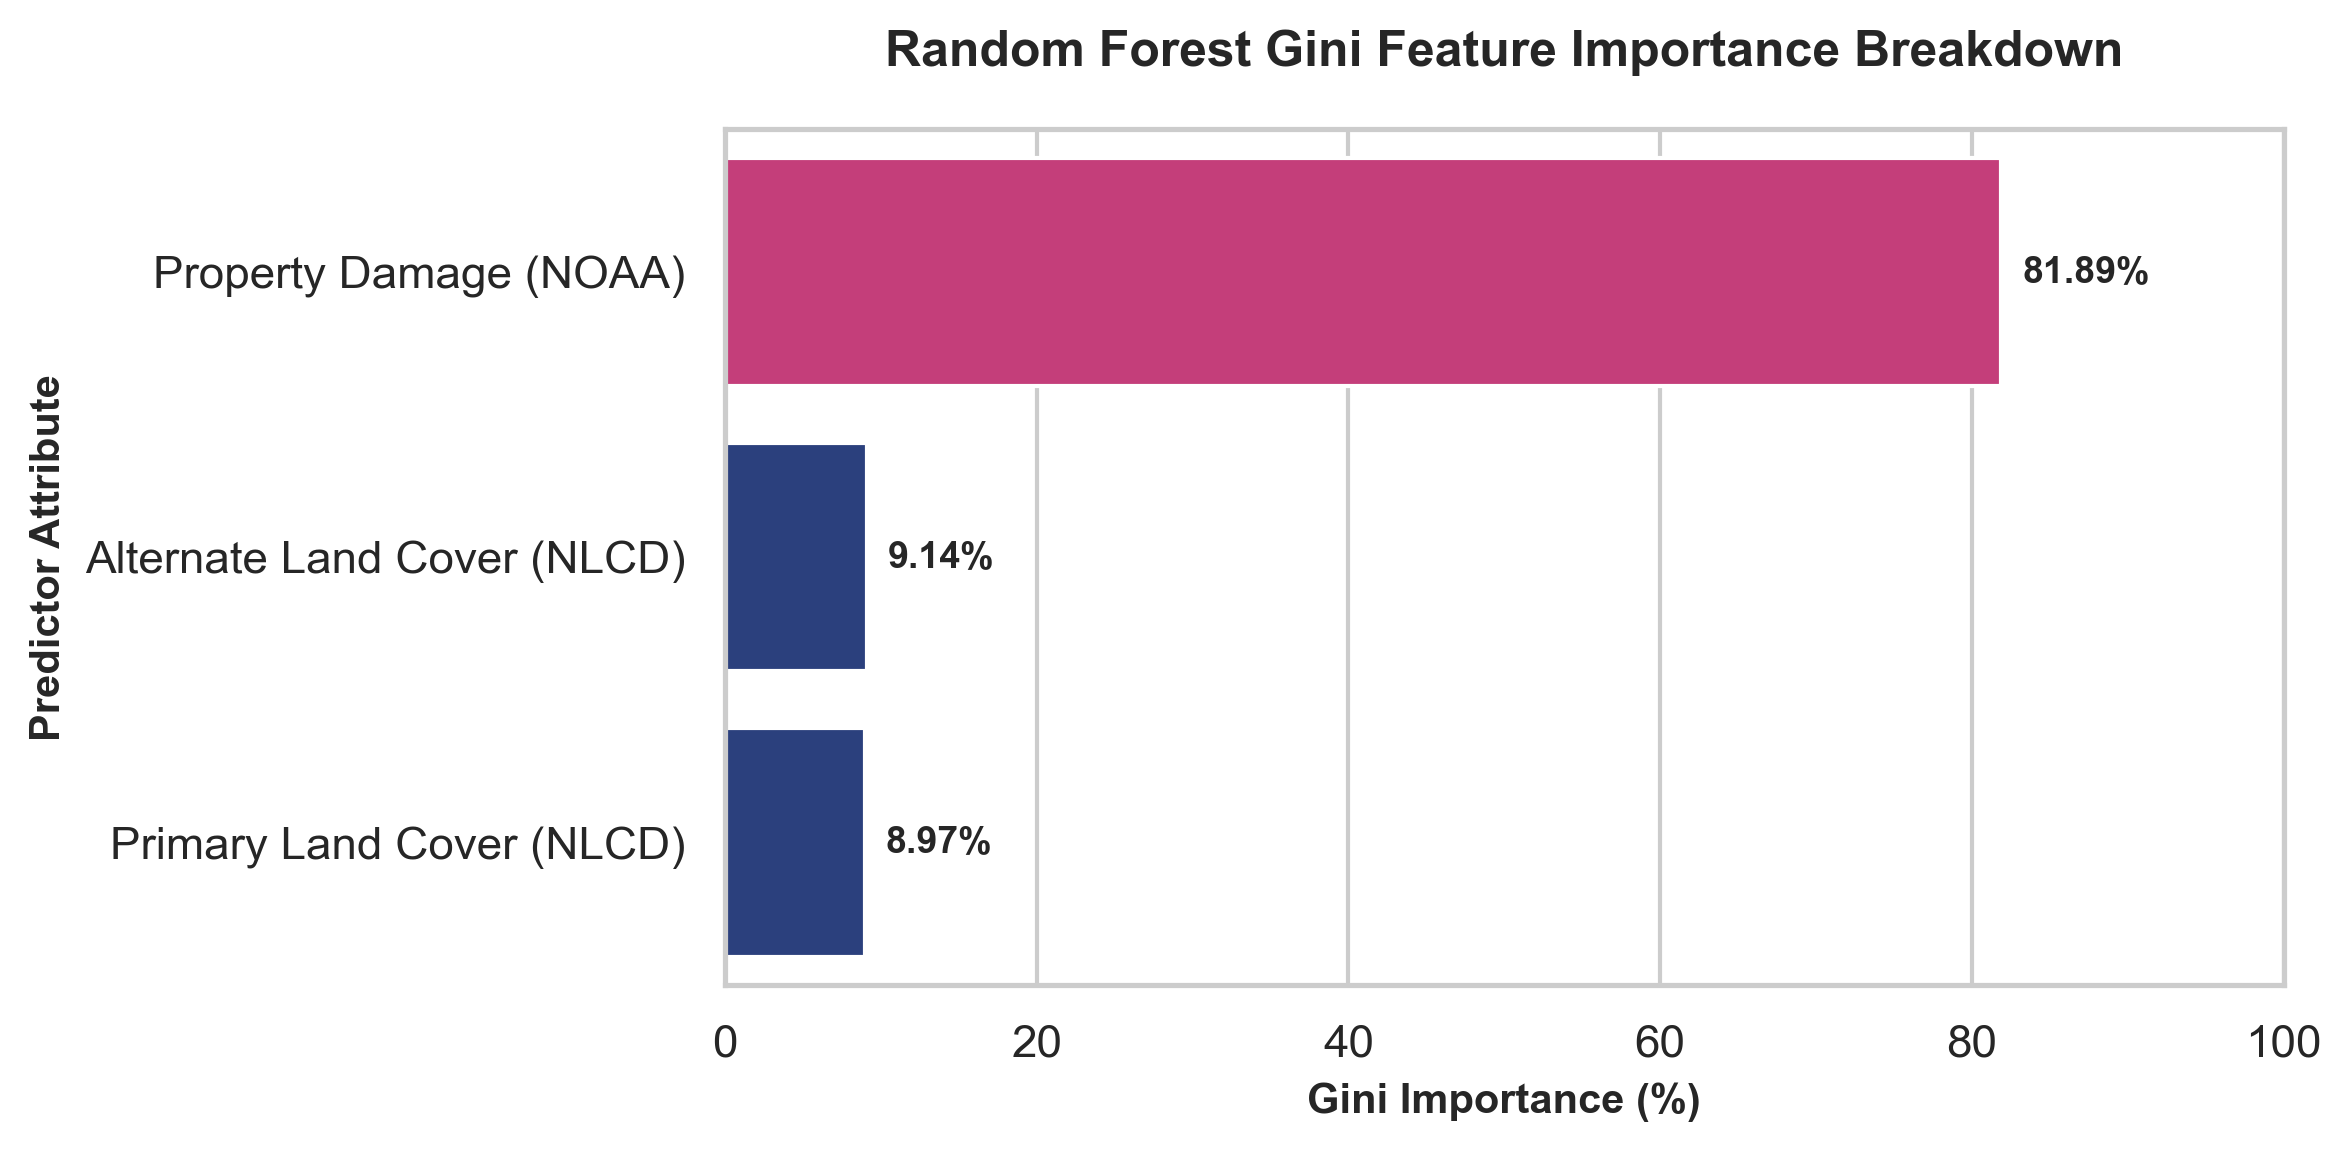

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Fix: Connect the DataFrame created in Cell 1 to feature_importance_df
feature_importance_df = importances.copy()

# Optional: Make feature names clean and publication-ready for your paper
feature_importance_df['Feature_Label'] = feature_importance_df['Feature'].map(
    {
        'DAMAGE_PROPERTY_NUMERIC': 'Property Damage (NOAA)',
        'alternate_landcover_code': 'Alternate Land Cover (NLCD)',
        'primary_landcover_code': 'Primary Land Cover (NLCD)',
    }
)

# Set academic plotting style
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 4), dpi=300)

# Color palette: Vibrant pink for top feature, deep navy for land cover features
custom_colors = ['#db2777', '#1e3a8a', '#1e3a8a']

ax = sns.barplot(
    data=feature_importance_df,
    x=feature_importance_df['Importance'] * 100,
    y='Feature_Label',
    palette=custom_colors,
    hue='Feature_Label',
    legend=False,
)

# Title and labels matching your paper narrative
plt.title(
    'Random Forest Gini Feature Importance Breakdown',
    fontsize=12,
    weight='bold',
    pad=15,
)
plt.xlabel('Gini Importance (%)', fontsize=10, weight='bold')
plt.ylabel('Predictor Attribute', fontsize=10, weight='bold')

# Set x-axis limit so labels don't get cut off
plt.xlim(0, 100)

# Annotate bars with exact percentages
for p in ax.patches:
  width = p.get_width()
  if width > 0:
    ax.annotate(
        f'{width:.2f}%',
        xy=(width, p.get_y() + p.get_height() / 2),
        xytext=(5, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=9,
        weight='bold',
    )

plt.tight_layout()

# Save image file to embed directly into your Word document
plt.savefig('week6_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()